In [1]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
import ipywidgets as wd
from astropy.time import Time
from matplotlib.ticker import MultipleLocator

In [2]:
#Getting all the data
search = lk.search_lightcurve("KIC 12557548", mission="Kepler", author="Kepler",
                              exptime="long", quarter=[2, 3, 4, 5, 6])
sap_flux_col = search.download_all(flux_column="sap_flux")

In [3]:
#Manipulating the data

stitched_data = sap_flux_col.stitch().remove_nans() #stitching the quarters together
convolved_data = stitched_data.flatten(window_length=31)  #convolving data to keep important signals
clipped_data = convolved_data.remove_outliers(   
    sigma_upper=2,
    sigma_lower=float("inf")
) #clipping the data to remove the upper spikes

In [4]:
#Eliminating data between 32.5-33.5 (MJD-550000). We believed they did this in the paper to eliminate some instrumental noise
clipped_time = clipped_data.time.mjd - 55000
final_data = clipped_data[(clipped_time < 32.5) | (clipped_time > 33.5)]

In [5]:
#Adjusting variables for Figure 2 as in paper
time = final_data.time.mjd - 55000 #original data is in BKJD, but in the paper they use (MJD - 55000). So first we transform the data to MJD and then substract 55000

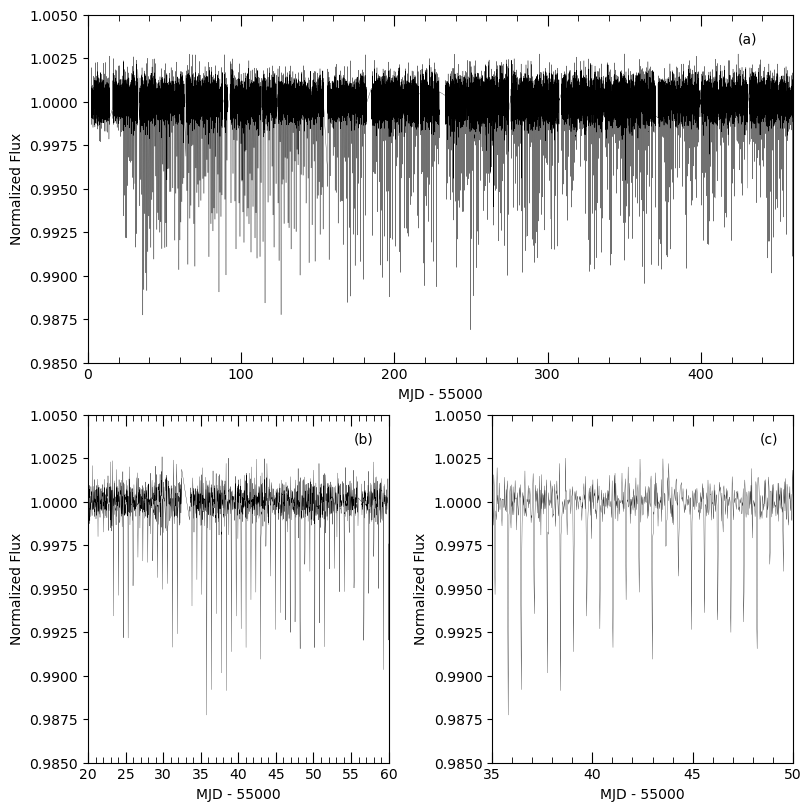

In [6]:
#Plotting Figure 2 of the paper
fig, ax = plt.subplot_mosaic(
    '''
    AA
    BC
    ''', 
    figsize = (8, 8), 
    constrained_layout = True
)

#Plotting A

ax['A'].plot(time, final_data.flux.value, color = "black", linestyle = "-", linewidth=0.2)

# Setting the axis of A

ax['A'].set_xlim(0,460)
ax['A'].set_ylim(0.985,1.005)

# Setting the labels of A

ax['A'].set_xlabel('MJD - 55000')
ax['A'].set_ylabel('Normalized Flux')

ax['A'].tick_params(axis='both', which='major', labelsize = 10)

#Adjusting the graph so that it looks like in the paper

#Adding the "(a)" on the top right

ax['A'].text(0.95, 0.95, '(a)',
             transform=ax['A'].transAxes,
             ha='right', va='top', fontsize=10)

#Making the axis clearer 

ax['A'].xaxis.set_major_locator(MultipleLocator(100))
ax['A'].xaxis.set_minor_locator(MultipleLocator(20))
ax['A'].tick_params(axis='x', which='major', direction='in', length=8)
ax['A'].tick_params(axis='x', which='minor', direction='in', length=4)
ax['A'].tick_params(axis='x', which='both', top=True)

###

#Plotting B

ax['B'].plot(time, final_data.flux.value, color = "black", linestyle = "-", linewidth=0.2)

# Setting the axis of B

ax['B'].set_xlim(20,60)
ax['B'].set_ylim(0.985,1.005)

# Setting the labels of B

ax['B'].set_xlabel('MJD - 55000')
ax['B'].set_ylabel('Normalized Flux')

ax['B'].tick_params(axis='both', which='major', labelsize = 10)

#Adjusting the graph so that it looks like in the paper

#Adding the "(b)" on the top right

ax['B'].text(0.95, 0.95, '(b)',
             transform=ax['B'].transAxes,
             ha='right', va='top', fontsize=10)

#Making the axis clearer 

ax['B'].xaxis.set_major_locator(MultipleLocator(5))
ax['B'].xaxis.set_minor_locator(MultipleLocator(1))
ax['B'].tick_params(axis='x', which='major', direction='in', length=8)
ax['B'].tick_params(axis='x', which='minor', direction='in', length=4)
ax['B'].tick_params(axis='x', which='both', top=True)

###

#Plotting C

ax['C'].plot(time, final_data.flux.value, color = "black", linestyle = "-", linewidth=0.2)

# Setting the axis of C

ax['C'].set_xlim(35,50)
ax['C'].set_ylim(0.985,1.005)

# Setting the labels of C

ax['C'].set_xlabel('MJD - 55000')
ax['C'].set_ylabel('Normalized Flux')

ax['C'].tick_params(axis='both', which='major', labelsize = 10)

#Adjusting the graph so that it looks like in the paper

#Adding the "(c)" on the top right

ax['C'].text(0.95, 0.95, '(c)',
             transform=ax['C'].transAxes,
             ha='right', va='top', fontsize=10)

#Making the axis clearer 

ax['C'].xaxis.set_major_locator(MultipleLocator(5))
ax['C'].xaxis.set_minor_locator(MultipleLocator(1))
ax['C'].tick_params(axis='x', which='major', direction='in', length=8)
ax['C'].tick_params(axis='x', which='minor', direction='in', length=4)
ax['C'].tick_params(axis='x', which='both', top=True)

###

plt.show()

In [7]:
#Adjusting variables for Figure 3 as in paper
period = 0.65356 #period used in paper, visible in equation 2
epoch_phase=0.5 #epoch time used in paper
epoch_time=567.324*u.day #For this Figure we don't have to plot in (MJD-55000). In equation 2 they give the epoch time= 55399.824 (MJD). So we need to adjust the epoch time to BKJD so that it matches the orginal data: 55399.824 (MJD) - 54832.5 = 567.324 (BKJD). 

In [8]:
#Folding data to create Figure 3
folded_data = final_data.fold(period=period, epoch_time=epoch_time, normalize_phase=True, epoch_phase=epoch_phase, wrap_phase=1)

In [9]:
#Binning the data for the second graph in Figure 3, the assumption warning is right
binned_data = folded_data.bin(bins=96)

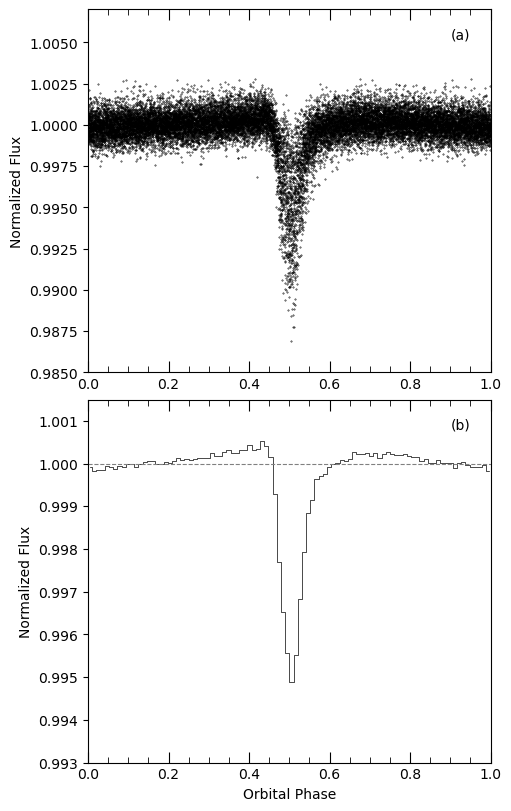

In [10]:
#Plotting Figure 3 of the paper
fig, ax = plt.subplot_mosaic(
    '''
    A
    B
    ''', 
    figsize = (5, 8), 
    constrained_layout = True
)

#Plotting A

folded_data.scatter(color="black", s=0.5, ax=ax['A'])
ax['A'].get_legend().remove()

# Setting the axis of A

ax['A'].set_xlim(0,1)
ax['A'].set_ylim(0.985,1.007)

# Setting the labels of A

ax['A'].set_xlabel('')
ax['A'].set_ylabel('Normalized Flux')
ax['A'].tick_params(axis='y', which='major', labelsize = 10)

#Adjusting the graph so that it looks like in the paper

#Adding the "(a)" on the top right

ax['A'].text(0.95, 0.95, '(a)',
             transform=ax['A'].transAxes,
             ha='right', va='top', fontsize=10)

#Making the axis clearer 

ax['A'].xaxis.set_major_locator(MultipleLocator(0.2))
ax['A'].xaxis.set_minor_locator(MultipleLocator(0.05))
ax['A'].tick_params(axis='x', which='major', direction='in', length=8)
ax['A'].tick_params(axis='x', which='minor', direction='in', length=4)
ax['A'].tick_params(axis='x', which='both', top=True)

###

#Plotting B

binned_data.plot(color="black", drawstyle="steps-mid", ax=ax['B'])
ax['B'].get_legend().remove()

# Setting the axis of B

ax['B'].set_xlim(0,1)
ax['B'].set_ylim(0.993,1.0015)

# Setting the labels of B

ax['B'].set_xlabel('Orbital Phase')
ax['B'].set_ylabel('Normalized Flux')
ax['B'].tick_params(axis='both', which='major', labelsize = 10)

#Adjusting the graph so that it looks like in the paper

#Adding the "(a)" on the top right

ax['B'].text(0.95, 0.95, '(b)',
             transform=ax['B'].transAxes,
             ha='right', va='top', fontsize=10)

#Making the axis clearer 
ax['B'].xaxis.set_major_locator(MultipleLocator(0.2))
ax['B'].xaxis.set_minor_locator(MultipleLocator(0.05))
ax['B'].tick_params(axis='x', which='major', direction='in', length=8)
ax['B'].tick_params(axis='x', which='minor', direction='in', length=4)
ax['B'].tick_params(axis='x', which='both', top=True)


#Adding the normalization line

plt.axhline(y=1, color="gray", linestyle="--", linewidth=0.8)

###

plt.show()